# 07 — Data quality: does the data need cleaning, and are some simulations useless?

Checks, from the raw files to the training tensors:

1. **Raw integrity** of the 20 batch files: non-finite values, values of `U`, initial
   temperature, duplicate rows, excitation settings.
2. **Targets**: valid ranges, physical consistency, outliers.
3. **Curves**: broken or implausible series (jumps, flat series, temperature dropping while heating).
4. **Outliers within identical-input groups** (the curves that do not look like the others
   receiving exactly the same input).
5. **Duplicate observations with different labels**.
6. **Uninformative simulations**: should they be removed?

Helpers: `ipe_prediction.eda.quality`, `ipe_prediction.eda.identifiability`.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)

from ipe_prediction.data import TARGET_NAMES
from ipe_prediction.eda import identifiability as I
from ipe_prediction.eda import plotting as P
from ipe_prediction.eda import quality as Q
from ipe_prediction.training.config import DataConfig
from ipe_prediction.training.dataset import prepare_data

P.set_style()
pd.set_option("display.precision", 3)
pd.set_option("display.width", 180)
hours = np.arange(480) / 60

## 1. Raw integrity (original batch files, before any processing)

In [2]:
raw = Q.scan_raw_batches(ROOT / "quentin_house")
display(raw)
print("totals:", raw[["n", "non-finite T", "non-finite U", "non-finite targets", "duplicate (T, U) rows"]].sum().to_dict())

,n,length,non-finite T,non-finite U,non-finite targets,U values (W),distinct T(0),T min,T max,"duplicate (T, U) rows",constant settings
file,,,,,,,,,,,
batch_1.pt,50000,480,0,0,0,"0, 7000",1,24.357,48.763,0,"max_power_wat, start_amplitude_wat, end_amplit..."
batch_2.pt,50000,480,0,0,0,"0, 7000",1,24.362,49.544,0,"max_power_wat, start_amplitude_wat, end_amplit..."
batch_3.pt,50000,480,0,0,0,"0, 7000",1,24.344,51.548,0,"max_power_wat, start_amplitude_wat, end_amplit..."
batch_4.pt,50000,480,0,0,0,"0, 7000",1,24.259,48.430,0,"max_power_wat, start_amplitude_wat, end_amplit..."
batch_5.pt,50000,480,0,0,0,"0, 7000",1,24.326,49.340,0,"max_power_wat, start_amplitude_wat, end_amplit..."
batch_6.pt,50000,480,0,0,0,"0, 7000",1,24.319,50.251,0,"max_power_wat, start_amplitude_wat, end_amplit..."
batch_7.pt,50000,480,0,0,0,"0, 7000",1,24.356,48.444,0,"max_power_wat, start_amplitude_wat, end_amplit..."
batch_8.pt,50000,480,0,0,0,"0, 7000",1,24.340,48.404,0,"max_power_wat, start_amplitude_wat, end_amplit..."
batch_9.pt,50000,480,0,0,0,"0, 7000",1,24.339,49.660,0,"max_power_wat, start_amplitude_wat, end_amplit..."


totals: {'n': 1000000, 'non-finite T': 0, 'non-finite U': 0, 'non-finite targets': 0, 'duplicate (T, U) rows': 0}


## 2. Targets

In [3]:
tensors, split = prepare_data(DataConfig())
dT, U, Y = tensors.delta_t, tensors.heater_on, tensors.targets.double()
N = len(Y)
hlc, mit, ext, tau_b, tau_n, tau_inf = Y.unbind(1)
checks = {
    "any target <= 0": int((Y <= 0).any(1).sum()),
    "|HLC - (mit + ext)| > 1e-3 W/K": int(((hlc - mit - ext).abs() > 1e-3).sum()),
    "tau_n > tau_inf": int((tau_n > tau_inf).sum()),
    "tau_inf > tau_b": int((tau_inf > tau_b).sum()),
}
display(pd.Series(checks, name="simulations").to_frame())

z = Q.robust_z(torch.cat([Y[:, :3], Y[:, 3:].log()], 1))  # time constants in log scale
display(pd.DataFrame({"|robust z| > 5": (z.abs() > 5).sum(0).numpy(), "|robust z| > 8": (z.abs() > 8).sum(0).numpy(),
                      "max |robust z|": z.abs().max(0).values.numpy()}, index=TARGET_NAMES))
extreme = z.abs().max(1).values
print(f"simulations with any target beyond |z| = 5: {(extreme > 5).sum():,} ({(extreme > 5).float().mean():.3%})")
display(pd.DataFrame(Y[extreme.argsort(descending=True)[:5]].numpy(), columns=TARGET_NAMES).round(2).rename_axis("5 most extreme"))

,simulations
any target <= 0,0
|HLC - (mit + ext)| > 1e-3 W/K,0
tau_n > tau_inf,0
tau_inf > tau_b,0


,|robust z| > 5,|robust z| > 8,max |robust z|
HLC,0,0,4.230
HLC_mit,0,0,4.044
HLC_ext,0,0,4.143
tau_b,0,0,4.645
tau_n,0,0,4.927
tau_inf,0,0,4.770


simulations with any target beyond |z| = 5: 0 (0.000%)


,HLC,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf
5 most extreme,,,,,,
0,156.05,76.49,79.57,88.87,25.84,64.10
1,173.63,94.94,78.69,105.96,25.44,80.88
2,144.60,60.61,83.99,122.88,23.57,93.12
3,129.26,68.07,61.19,106.95,25.08,78.68
4,158.73,87.89,70.83,87.55,24.55,64.02


## 3. Curves: broken or implausible series

In [4]:
stats = Q.curve_anomalies(dT, U)
display(stats.describe(percentiles=[0.001, 0.01, 0.5, 0.99, 0.999]).T)
flags = {
    "1-min jump > 0.5 °C": stats["max 1-min jump"] > 0.5,
    "below the start by > 0.5 °C": stats["min rise"] < -0.5,
    "drops > 0.1 °C over 1 h of continuous heating": stats["max 1-h drop while heating"] > 0.1,
    "almost flat (< 5 distinct values)": stats["distinct values"] < 5,
}
display(pd.Series({k: int(v.sum()) for k, v in flags.items()}, name="simulations").to_frame())

,count,mean,std,min,0.1%,1%,50%,99%,99.9%,max
max 1-min jump,1000000.0,0.414,0.121,0.01,0.01,0.01,0.45,0.47,0.48,0.50
final rise,1000000.0,8.267,4.831,0.44,0.77,0.95,8.11,17.59,19.92,26.93
min rise,1000000.0,-0.004,0.016,-0.40,-0.16,-0.08,0.00,0.00,0.00,0.00
max 1-h drop while heating,1000000.0,-0.004,0.043,-0.82,-0.55,-0.00,-0.00,0.00,0.00,-0.00
distinct values,1000000.0,380.477,102.448,64.00,95.00,113.00,417.00,480.00,480.00,480.00


,simulations
1-min jump > 0.5 °C,0
below the start by > 0.5 °C,0
drops > 0.1 °C over 1 h of continuous heating,0
almost flat (< 5 distinct values),0


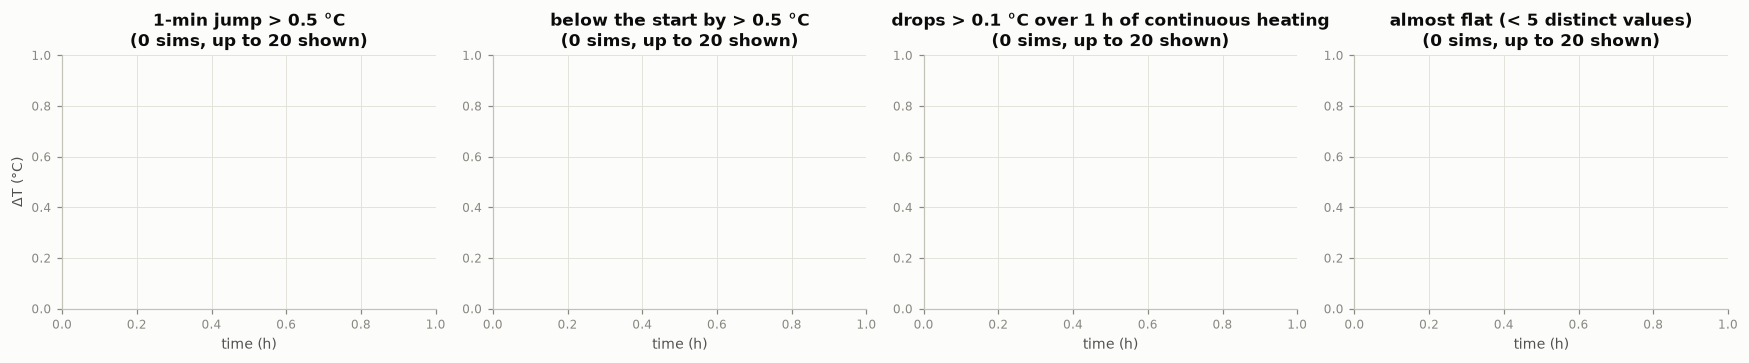

In [5]:
fig, axes = plt.subplots(1, len(flags), figsize=(16, 3.4))
for ax, (name, mask) in zip(axes, flags.items()):
    idx = np.flatnonzero(mask.to_numpy())[:20]
    for i in idx:
        ax.plot(hours, dT[i].numpy(), lw=0.8)
    ax.set(title=f"{name}\n({mask.sum():,} sims, up to 20 shown)", xlabel="time (h)")
axes[0].set_ylabel("ΔT (°C)")
fig.tight_layout()

## 4. Outliers within identical-input groups

For each group of at least 1,000 simulations with exactly the same input, the largest robust
z-score of a curve against the other curves of its group (over time, 5-min resolution). A large
score means a curve unlike the others **for the same input**: either a broken simulation, or a
building at the edge of the population. Comparing with the targets tells which.

In [6]:
group, size = I.input_groups(U)
score = Q.group_outliers(dT[:, ::5], group)
valid = ~score.isnan()
print(f"simulations scored: {int(valid.sum()):,}")
display(pd.Series({f"> {k}": float((score[valid] > k).float().mean()) for k in (3, 5, 8, 12)}, name="share of curve outliers").to_frame().T)

target_extreme = Q.robust_z(torch.cat([Y[:, :3], Y[:, 3:].log()], 1)).abs().max(1).values
top = score.nan_to_num(-1).argsort(descending=True)[:2000]
rest = valid.nonzero().flatten()[torch.randperm(int(valid.sum()))[:20000]]
display(pd.DataFrame({
    "2,000 most outlying curves": [float(target_extreme[top].median()), float((target_extreme[top] > 3).float().mean())],
    "random simulations": [float(target_extreme[rest].median()), float((target_extreme[rest] > 3).float().mean())],
}, index=["median max |z| of the targets", "share with a target beyond |z| = 3"]))

simulations scored: 650,317


,> 3,> 5,> 8,> 12
share of curve outliers,0.029,5.674e-04,1.538e-06,0.0


,"2,000 most outlying curves",random simulations
median max |z| of the targets,1.876,1.317
share with a target beyond |z| = 3,0.019,0.008


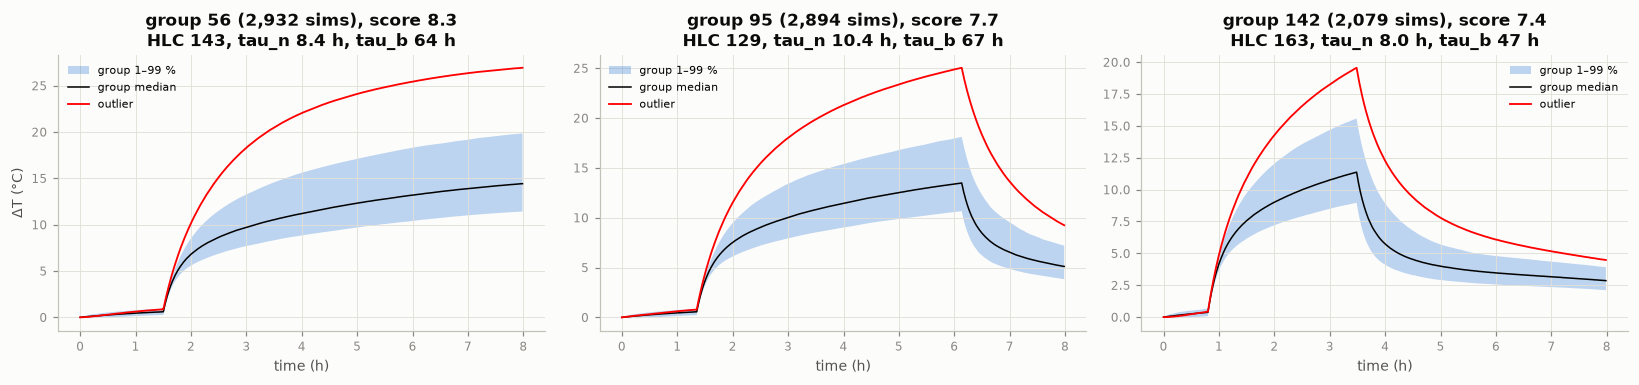

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=False)
for ax, i in zip(axes, top[:3]):
    g = group[i]
    members = (group == g).nonzero().flatten()
    band = dT[members]
    ax.fill_between(hours, band.quantile(0.01, 0).numpy(), band.quantile(0.99, 0).numpy(), alpha=0.3, label="group 1–99 %")
    ax.plot(hours, band.median(0).values.numpy(), "k", lw=1, label="group median")
    ax.plot(hours, dT[i].numpy(), "r", lw=1.2, label="outlier")
    y6 = Y[i]
    ax.set(title=f"group {int(g)} ({len(members):,} sims), score {score[i]:.1f}\nHLC {y6[0]:.0f}, tau_n {y6[4]:.1f} h, tau_b {y6[3]:.0f} h",
           xlabel="time (h)")
    ax.legend(fontsize=7)
axes[0].set_ylabel("ΔT (°C)")
fig.tight_layout()

## 5. Duplicate observations with different labels

Simulations with the same input and the same curve (at the 0.01 °C resolution of the data). If
their targets differ, no model can tell them apart: an exact, irreducible error.

In [8]:
dup = Q.contradictory_duplicates(dT, U, tensors.targets)
display(pd.Series(dup, name="simulations").to_frame())

,simulations
simulations with a duplicate observation,0
of which with different targets,0


## 6. Uninformative simulations: remove them?

Simulations where the input carries little or no information on some targets (from notebook 06:
unheated tests say almost nothing about HLC; near-zero duty cycles are as poor).

In [9]:
duty = torch.cat([u.float().mean(1) for u in U.split(100_000)])
low = {
    "never heated (duty = 0)": duty == 0,
    "barely heated (0 < duty < 0.05)": (duty > 0) & (duty < 0.05),
    "always heated (duty = 1)": duty == 1,
}
display(pd.Series({k: f"{int(m.sum()):,} ({m.float().mean():.1%})" for k, m in low.items()}, name="simulations").to_frame())

,simulations
never heated (duty = 0),"84,164 (8.4%)"
barely heated (0 < duty < 0.05),"10,330 (1.0%)"
always heated (duty = 1),"8,711 (0.9%)"


## 7. Conclusion: the data is clean; nothing should be removed

**1. Raw files: no defect.** 20 × 50,000 simulations of 480 steps, no NaN or infinite value in
temperatures, power or targets, no duplicate (T, U) row. `U` takes only the values 0 and 7000 W,
and every simulation starts from the same indoor temperature. Of the 12 excitation settings, 9 are
constant (7 kW, sinusoid amplitudes and periods all 0, PRBS seed 42): every test is a PRBS at full
power, and only the PRBS minimum duration, maximum duration and probability of being on vary.
They are drawn continuously (980k distinct values) but produce only 2,798 distinct sequences at
1-min resolution: the settings are metadata, the sequence `U(t)` is what matters.

**2. Targets: consistent and without outliers.** All positive; `HLC = HLC_mit + HLC_ext` holds
exactly; `tau_n <= tau_inf <= tau_b` holds for every simulation; no target has a robust z-score
beyond 5 (max 4.9): the building parameters were sampled within bounded ranges, with no extreme
or erroneous values.

**3. Curves: no broken series.** The largest 1-min jump is 0.50 °C, which is the normal response
of the air to the heater switching on (median 0.45 °C over the series that switch); no curve falls
more than 0.4 °C below its start, none ever drops during an hour of continuous heating, and every
series has at least 64 distinct values (no flat or frozen series).

**4. Outliers within identical-input groups are legitimate buildings.** Among the 650k simulations
in groups of ≥ 1,000 identical inputs, 2.9 % of curves exceed a robust z-score of 3 and only 0.06 %
exceed 5 (none beyond 12). The most outlying curves belong to buildings slightly more extreme than
average (1.9 % with a target beyond |z| = 3, vs 0.8 % at random): they are the edges of the
population, not simulation errors. Removing them would only make the model worse on such buildings.

**5. No contradictory duplicates.** No two simulations share the same input and the same curve,
so there is no exact case of identical observations with different labels. The ambiguity found
in notebook 06 is approximate (near-identical curves), which is physics, not a data error.

**6. Uninformative simulations should be kept.** 8.4 % are never heated and 1.0 % barely heated
(duty < 0.05): they carry almost no information on HLC, but they are the most informative tests
for `HLC_ext` and `tau_b` (notebook 06), the model recognises them from their input, and
notebook 05 showed that training without uninformative tests brings no gain on the informative
ones while losing all ability to handle other protocols.

**Answer:** the dataset needs **no cleaning**. It is a clean, noise-free simulation output (only the
0.01 °C rounding of the assessment), and no subset of simulations hinders learning. The
difficulty is entirely in the physics: an 8 h test does not determine the six indicators.